<a href="https://colab.research.google.com/github/Andre-Victor-Vasconcelos/Redes-Neurais-Artificiais---Francisco-de-Assis-Boldt/blob/main/Implementa%C3%A7%C3%A3o_Backpropagation_MLP.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

In [2]:
class CustomMLP:
    def __init__(self, layer_sizes, activations, learning_rate=0.1, epochs=1000):
        """
        layer_sizes: lista com a quantidade de neurônios. Ex: [2, 4, 1] (2 entradas, 4 na oculta, 1 saída)
        activations: lista com as funções de ativação de cada camada. Ex: ['relu', 'sigmoid']
        """
        assert len(layer_sizes) - 1 == len(activations), "A quantidade de ativações deve ser igual à de camadas (excluindo a entrada)."

        self.layer_sizes = layer_sizes
        self.activations = activations
        self.learning_rate = learning_rate
        self.epochs = epochs

        self.weights = []
        self.biases = []
        self.loss_history = []

        # Inicializando os pesos (He/Xavier Initialization simplificado)
        for i in range(len(layer_sizes) - 1):
            w = np.random.randn(layer_sizes[i], layer_sizes[i+1]) * np.sqrt(2. / layer_sizes[i])
            b = np.zeros((1, layer_sizes[i+1]))
            self.weights.append(w)
            self.biases.append(b)

    # --- Funções de Ativação e suas Derivadas ---
    def _activate(self, Z, func_name):
        if func_name == 'relu':
            return np.maximum(0, Z)
        elif func_name == 'sigmoid':
            return 1 / (1 + np.exp(-np.clip(Z, -500, 500))) # clip evita overflow
        elif func_name == 'tanh':
            return np.tanh(Z)
        raise ValueError(f"Ativação {func_name} não suportada.")

    def _derivative(self, Z, func_name):
        if func_name == 'relu':
            return (Z > 0).astype(float)
        elif func_name == 'sigmoid':
            s = 1 / (1 + np.exp(-np.clip(Z, -500, 500)))
            return s * (1 - s)
        elif func_name == 'tanh':
            return 1 - np.tanh(Z)**2
        raise ValueError(f"Ativação {func_name} não suportada.")

    # --- Forward Pass (Propagação Direta) ---
    def forward(self, X):
        self.A = [X] # Guarda as ativações
        self.Z = []  # Guarda os pré-ativados (Z = WX + b)

        A_curr = X
        for i in range(len(self.weights)):
            Z_curr = np.dot(A_curr, self.weights[i]) + self.biases[i]
            self.Z.append(Z_curr)

            A_curr = self._activate(Z_curr, self.activations[i])
            self.A.append(A_curr)

        return A_curr

    # --- Treinamento ---
    def fit(self, X, y):
        m = X.shape[0]
        y = y.reshape(-1, 1)

        for epoch in range(self.epochs):
            # 1. Forward pass
            y_pred = self.forward(X)

            # Cálculo da perda (MSE)
            loss = np.mean(0.5 * (y_pred - y)**2)
            self.loss_history.append(loss)

            # 2. Backpropagation
            # Derivada do MSE em relação a ativação final: dA = (y_pred - y)
            dA = (y_pred - y)

            for i in reversed(range(len(self.weights))):
                dZ = dA * self._derivative(self.Z[i], self.activations[i])
                dW = np.dot(self.A[i].T, dZ) / m
                db = np.sum(dZ, axis=0, keepdims=True) / m

                # Prepara o dA para a camada anterior
                dA = np.dot(dZ, self.weights[i].T)

                # Atualização dos pesos (Gradient Descent)
                self.weights[i] -= self.learning_rate * dW
                self.biases[i] -= self.learning_rate * db

    # --- Predição ---
    def predict(self, X):
        y_pred = self.forward(X)
        return (y_pred >= 0.5).astype(int) # Para classificação binária

Acurácia do Custom MLP: 97.00%


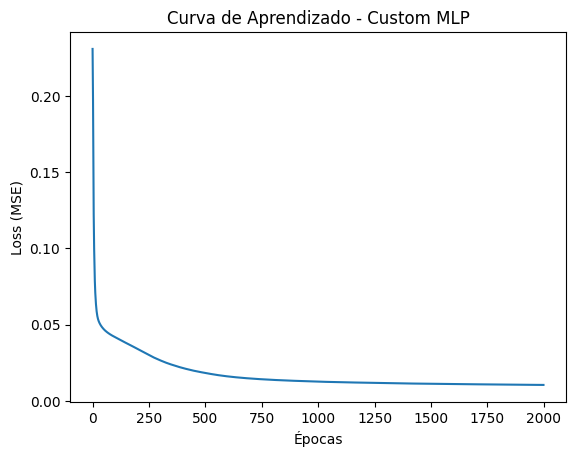

In [4]:
# Gerando os dados
X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Definindo a arquitetura:
# 2 features na entrada -> 1ª Oculta com 8 neurônios (ReLU) -> 2ª Oculta com 4 neurônios (Tanh) -> Saída com 1 (Sigmoid)
camadas = [2, 8, 4, 1]
ativacoes = ['relu', 'tanh', 'sigmoid']

# Inicializando e treinando
meu_mlp = CustomMLP(layer_sizes=camadas, activations=ativacoes, learning_rate=0.5, epochs=2000)
meu_mlp.fit(X_train, y_train)

# Avaliando
y_pred_meu = meu_mlp.predict(X_test)
acc_meu = accuracy_score(y_test, y_pred_meu)
print(f"Acurácia do Custom MLP: {acc_meu * 100:.2f}%")

# Plot da curva de erro (Loss)
plt.plot(meu_mlp.loss_history)
plt.title("Curva de Aprendizado - Custom MLP")
plt.xlabel("Épocas")
plt.ylabel("Loss (MSE)")
plt.show()

In [5]:
# Scikit-learn MLP Classifier
# Note que o sklearn exige apenas as camadas ocultas no parâmetro hidden_layer_sizes
# E a ativação é uma só para todas as camadas ocultas.
sklearn_mlp = MLPClassifier(hidden_layer_sizes=(8, 4),
                            activation='relu', # Sklearn não permite 'relu' na primeira e 'tanh' na segunda
                            solver='sgd',
                            learning_rate_init=0.5,
                            max_iter=2000,
                            random_state=42,
                            momentum=0.0) # Tirando o momentum para ficar puramente igual ao nosso Gradient Descent

sklearn_mlp.fit(X_train, y_train)
y_pred_sklearn = sklearn_mlp.predict(X_test)
acc_sklearn = accuracy_score(y_test, y_pred_sklearn)

print(f"Acurácia do Scikit-Learn MLP: {acc_sklearn * 100:.2f}%")

Acurácia do Scikit-Learn MLP: 97.33%


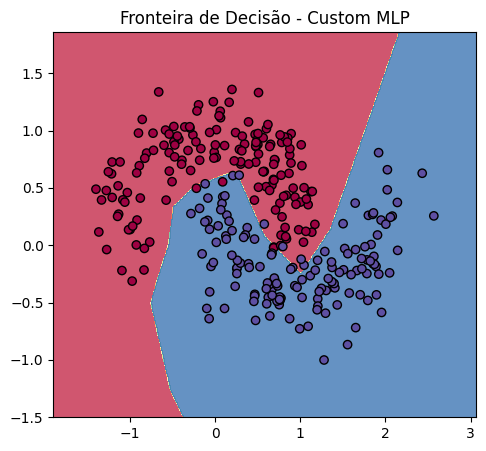

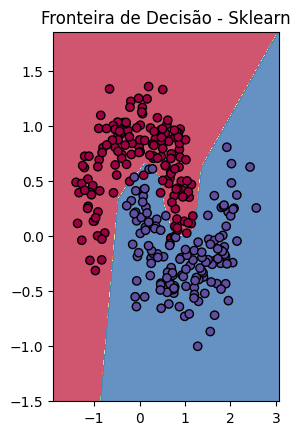

In [6]:
def plot_decision_boundary(model, X, y, title, is_custom=True):
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01),
                         np.arange(y_min, y_max, 0.01))

    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    if is_custom:
        Z = Z.reshape(xx.shape)
    else:
        Z = Z.reshape(xx.shape)

    plt.contourf(xx, yy, Z, alpha=0.8, cmap=plt.cm.Spectral)
    plt.scatter(X[:, 0], X[:, 1], c=y, edgecolors='k', cmap=plt.cm.Spectral)
    plt.title(title)
    plt.show()

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plot_decision_boundary(meu_mlp, X_test, y_test, "Fronteira de Decisão - Custom MLP", is_custom=True)

plt.subplot(1, 2, 2)
plot_decision_boundary(sklearn_mlp, X_test, y_test, "Fronteira de Decisão - Sklearn", is_custom=False)